# Setup
## Dependencies

In [69]:
%config InlineBackend.figure_format = 'retina'
from astropy.io import fits
from astropy import units as u
from astropy.coordinates import SkyCoord
import numpy as np
import matplotlib.pyplot as plt
from astropy.wcs import WCS
from photutils.centroids import centroid_quadratic
from photutils.aperture import CircularAnnulus, CircularAperture, ApertureStats, aperture_photometry
import sqlite3
from pathlib import Path
import re

import warnings
from astropy.wcs import FITSFixedWarning
from astropy.utils.exceptions import AstropyUserWarning

warnings.filterwarnings("ignore", category=FITSFixedWarning)
warnings.filterwarnings("ignore", category=AstropyUserWarning)

In [57]:
db_path = Path("../databases/Master_Database.db").resolve()
conn = sqlite3.connect(db_path)
nonflat_mosaic_folder = Path("../output mosaics/non-flats")

## Coordinate Dictionary

In [58]:
sn_coordinates = {
    "aepk": ("02h09m55.997s", "+10d45m36.17s"),
    "abxl": ("13h23m45.388s", "+31d33m52.17s"),
    "acna": ("01h48m51.954s", "+10d35m11.40s"),
    "aaiv": ("22h37m05.618s", "+34d24m35.37s"),
    "aeiv": ("03h16m41.828s", "+80d48m09.12s"),
    "aesj": ("07h48m40.014s", "+54d36m43.62s"),
    "afsg": ("12h02m02.958s", "+29d50m40.95s"),
    "acpp": ("09h48m42.410s", "+44d04m27.20s"),
}

# Functions
## get_centroid

In [59]:
def get_centroid(image_data, wcs, obj_RA, obj_Dec):
    coord_ra_dec =  SkyCoord(obj_RA, obj_Dec)
    # in form of SkyCoord('22h37m05s', '+34d24m35.37s')

    target_x, target_y = wcs.world_to_pixel(coord_ra_dec)

    supernova_xy_center = centroid_quadratic(
        image_data, 
        xpeak = target_x, 
        ypeak = target_y,
        search_boxsize=11, 
        fit_boxsize=5,
    )

    return(supernova_xy_center)

## open_fits

In [60]:
def open_fits(img_path):
    image = fits.open(img_path)
    img_data = image[0].data
    img_header = image[0].header
    wcs = WCS(img_header)

    clean_data = np.nan_to_num(img_data, nan=0.0)
    
    return(clean_data, wcs)

## make_apertures

In [61]:
def make_apertures(target_coords, aperture_radius, annulus_inner, annulus_outer):
    
    apertures = CircularAperture(
        target_coords, 
        r=aperture_radius
    )
    
    annuli = CircularAnnulus(
        target_coords, 
        r_in=annulus_inner, 
        r_out=annulus_outer
    )

    return(apertures, annuli)

## plot_zoom_section

In [62]:
def plot_zoom_section(image_data, target_coords, apertures, annuli):
    img_mean, img_sigma = np.mean(image_data), np.std(image_data)
    
    zoom_height = 200
    zoom_width = zoom_height * 1.5
    section_ymin, section_ymax = (target_coords[1] - zoom_height/2), (target_coords[1] + zoom_height/2)
    section_xmin, section_xmax = (target_coords[0] - zoom_width/2), (target_coords[0] + zoom_width/2)
    section = image_data[int(section_ymin):int(section_ymax), int(section_xmin):int(section_xmax)]

    
    plt.imshow(
        image_data,
        vmin = img_mean - 1 * img_sigma,
        vmax =  img_mean + 5 * img_sigma,
        cmap = 'grey',
        origin='lower',
        interpolation='nearest',
    )
    apertures.plot(color = 'blue', lw = .7, alpha = 1);
    annuli.plot(color = 'red', lw = .7, alpha = 1);
    plt.xlabel('X position (pixels)')
    plt.ylabel('Y position (pixels)')
    
    #cbar = plt.colorbar()
    #cbar.set_label('Counts (ADU)')
    #plt.title(f'{Star_Name} and {Comp_Star_Name} (Green Channel)')


    plt.xlim(section_xmin,section_xmax)
    plt.ylim(section_ymax,section_ymin)
    #plt.savefig(f'../graphs/{Star_Name}_{Comp_Star_Name}-Zoomed_Image.png', dpi=300, bbox_inches='tight')

    plt.scatter(
        target_coords[0], target_coords[1], 
        s=30, color='red', marker='+', linewidth = 0.5,
        label='Centroid',
    )
    plt.show()

## conduct_photometry

In [63]:
def conduct_photometry(image_data, aperture, annuli, zpt):
    phot_table = aperture_photometry(image_data, [aperture, annuli]) 
    C_aper = phot_table['aperture_sum_0'] 
    C_annul = phot_table['aperture_sum_1'] 
    N_aper = aperture.area
    N_annul = annuli.area 

    C_sky = N_aper * (C_annul/N_annul)
    C_obj = C_aper - C_sky

    obj_mag = -2.5 * (np.log10(C_obj)) + zpt

    return float(obj_mag[0])

## get_empty_list

In [67]:
def get_empty_list(conn):
    work_sql = """
        SELECT group_id, object, mosaic_name, zpt_median
        FROM observations
        WHERE mosaic_name IS NOT NULL
            AND zpt_median IS NOT NULL
            AND mag IS NULL
            AND error IS NULL
        ORDER BY group_id
    """
    work_query = conn.execute(work_sql).fetchall()
    
    #print(len(work_list))

    return(work_query)

## insert_photometry

In [65]:
def insert_photometry(conn, work_list, mosaic_folder, sn_coordinates,
                      aperture_radius, annulus_inner, annulus_outer,
                      max_centroid_distance, show_plots):
    save_mag_sql = """
        UPDATE observations
        SET mag = ?
        WHERE group_id = ?
            AND mag IS NULL
            AND error IS NULL
    """
    save_error_sql = """
        UPDATE observations
        SET error = ?
        WHERE group_id = ?
            AND mag IS NULL
            AND error IS NULL
    """
    
    mags_saved = 0
    errors_saved = 0
    
    with conn:
        for group_id, object_name, mosaic_name, zpt in work_list:
     
            short_sn_name = object_name[-4:].lower()
            obj_RA, obj_Dec = sn_coordinates[short_sn_name]
    
            full_mosaic_file = mosaic_folder / mosaic_name
            image_data, wcs = open_fits(full_mosaic_file)
            
            supernova_position = SkyCoord(obj_RA, obj_Dec)
            predicted_x, predicted_y = wcs.world_to_pixel(supernova_position)
    
            image_height, image_width = image_data.shape
    
            inside_x = 0 <= predicted_x < image_width
            inside_y = 0 <= predicted_y < image_height
    
            if not (inside_x and inside_y):
                message = "photometry: target outside image"
                cursor = conn.execute(save_error_sql, (message, group_id))
                
                errors_saved = errors_saved + cursor.rowcount
                print(group_id, mosaic_name, " ", message)
                
                continue
    
            target_coords = get_centroid(image_data, wcs, obj_RA, obj_Dec)
    
            centroid_x = target_coords[0]
            centroid_y = target_coords[1]
    
            if not (np.isfinite(centroid_x) and np.isfinite(centroid_y)):
                message = "photometry: no centroid"
                cursor = conn.execute(save_error_sql, (message, group_id))
                
                errors_saved = errors_saved + cursor.rowcount
                print(group_id, mosaic_name, " ", message)
                
                continue
    
            
            delta_x = centroid_x - predicted_x
            delta_y = centroid_y - predicted_y
            distance = np.sqrt(delta_x**2 + delta_y**2)
    
            if distance > max_centroid_distance:
                message = f"photometry: centroid too far ({distance:.1f} px)"
                cursor = conn.execute(save_error_sql, (message, group_id))
                
                errors_saved = errors_saved + cursor.rowcount
                print(group_id, mosaic_name, " ", message)
                
                continue




            
            apertures, annuli = make_apertures(target_coords, aperture_radius, annulus_inner, annulus_outer)
    
            if show_plots == True:
                plot_zoom_section(image_data, target_coords, apertures, annuli)
    
            obj_mag = conduct_photometry(image_data, apertures, annuli, zpt)

            
            if not np.isfinite(obj_mag):
                message = "photometry: no flux"
                cursor = conn.execute(save_error_sql, (message, group_id))
                
                errors_saved = errors_saved + cursor.rowcount
                print(group_id, mosaic_name, " ", message)
                
                continue
    
            
            cursor = conn.execute(save_mag_sql, (obj_mag, group_id))
            mags_saved = mags_saved + cursor.rowcount
    
    return(mags_saved, errors_saved)

# Actual Photometry

In [75]:
aperture_radius = 12
annulus_inner = 18
annulus_outer = 24
max_centroid_distance = 2      
show_plots = False

work_list = get_empty_list(conn)

#print("Mosaics to measure:", len(work_list))

mags_saved, errors_saved = insert_photometry(
    conn, work_list, nonflat_mosaic_folder,
    sn_coordinates, aperture_radius, annulus_inner,
    annulus_outer, max_centroid_distance, show_plots,
)

print("Number of magnitudes stored:", mags_saved)
print("Number of errors:", errors_saved)

2 at2026aesj-26_10_13-pt5m-B-g2-mosaic.fits   photometry: no centroid
78 sn2026aaiv-26_09_24-pt5m-I-g78-mosaic.fits   photometry: centroid too far (3.1 px)
107 sn2026acna-26_10_07-pt5m-I-g107-mosaic.fits   photometry: centroid too far (3.7 px)
124 sn2026acna-26_10_01-pt5m-I-g124-mosaic.fits   photometry: centroid too far (5.6 px)
129 sn2026acna-26_09_29-pt5m-R-g129-mosaic.fits   photometry: centroid too far (2.3 px)
135 sn2026acpp-26_10_11-pt5m-I-g135-mosaic.fits   photometry: centroid too far (2.6 px)
136 sn2026acpp-26_10_11-pt5m-R-g136-mosaic.fits   photometry: no centroid
137 sn2026acpp-26_10_11-pt5m-V-g137-mosaic.fits   photometry: no centroid
141 sn2026acpp-26_10_10-pt5m-V-g141-mosaic.fits   photometry: no centroid
142 sn2026acpp-26_10_10-pt5m-B-g142-mosaic.fits   photometry: no centroid
143 sn2026acpp-26_10_06-pt5m-I-g143-mosaic.fits   photometry: no centroid
144 sn2026acpp-26_10_06-pt5m-R-g144-mosaic.fits   photometry: centroid too far (2.0 px)
145 sn2026acpp-26_10_06-pt5m-V-g14

Centroid: [470.36612703 460.72692575]


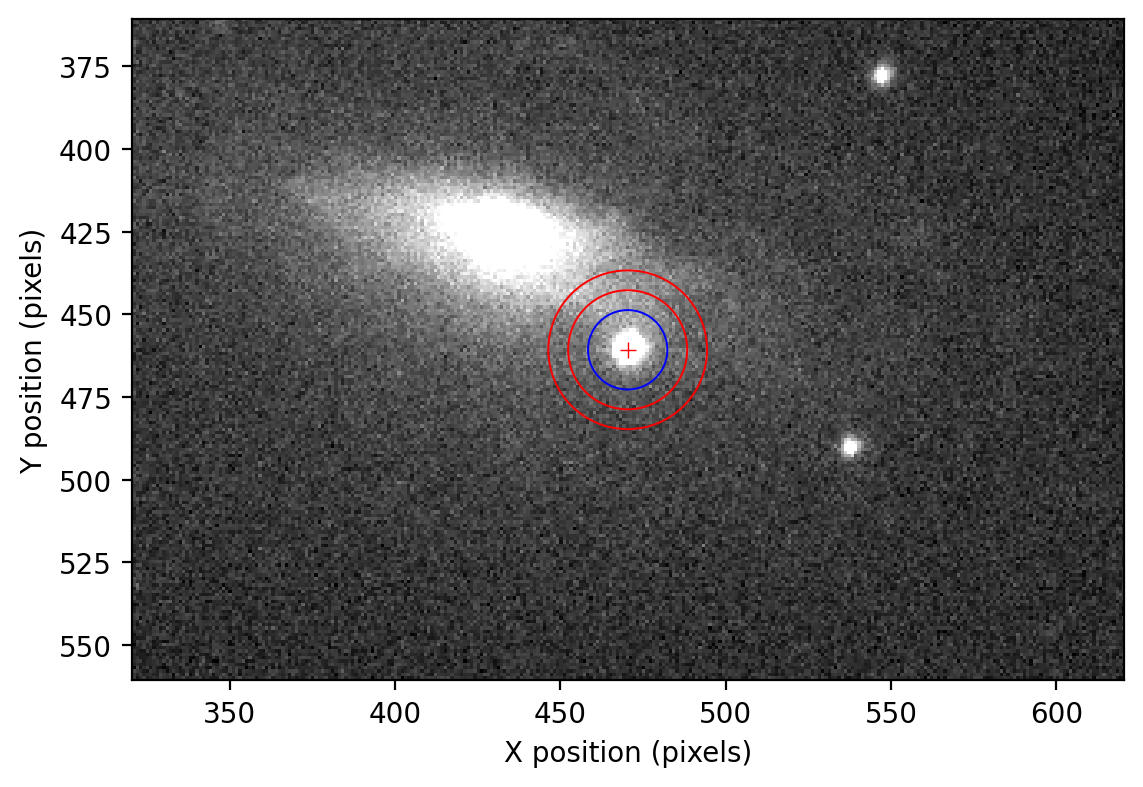

NameError: name 'zpt' is not defined

In [49]:
for file in list:
    name1 = re.match(r"(?:at|sn)\d{4}([a-z]+)-", Path(file).name, re.IGNORECASE)
    SN_name = name1.group(1).lower()

    aperture_radius = 12
    annulus_inner = 18
    annulus_outer = 24

    obj_RA, obj_Dec = sn_coordinates[SN_name]
    
    image_data = open_fits(file)[0]
    wcs = open_fits(file)[1]

    target_coords = get_centroid(image_data, obj_RA, obj_Dec)
    print("Centroid:", target_coords)

    apertures = make_apertures(target_coords, aperture_radius, annulus_inner, annulus_outer)[0]
    annuli = make_apertures(target_coords, aperture_radius, annulus_inner, annulus_outer)[1]

    plot_zoom_section(image_data, target_coords, apertures, annuli)

    obj_mag = conduct_photometry(image_data, apertures, annuli, zpt)